In [2]:
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Montar Google Drive (te pedirá permiso en una ventana emergente)
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Reemplaza con la ruta de tu archivo (puedes copiarla desde el panel izquierdo de archivos en Colab)
ruta = '/content/drive/MyDrive/datos_prueba.csv'

# Cargar CSV (cambia sep=',' por sep=';' si tus columnas están separadas por punto y coma)
df = pd.read_csv(ruta, sep=',')

# Si tu archivo es Excel (.xlsx), comenta la línea anterior y usa esta:
# df = pd.read_excel(ruta)

print(f'Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas')
display(df.head())

Dimensiones del dataset: 100 filas y 8 columnas


,id_registro,fecha,categoria,zona,cantidad,precio_unitario,satisfaccion,total_venta
0,1,2026-01-01,Ropa,Sur,12,198.83,4.0,2385.96
1,2,2026-01-02,Alimentos,Centro,12,246.78,2.0,2961.36
2,3,2026-01-03,Electrónica,Centro,11,233.41,2.0,2567.51
3,4,2026-01-04,Ropa,Centro,7,90.13,5.0,630.91
4,5,2026-01-05,Ropa,Centro,1,253.58,2.0,253.58


In [4]:
# Tipos de datos y memoria
df.info()

# Conteo de valores nulos por columna
print('\nValores nulos por columna:')
print(df.isnull().sum())

# Resumen estadístico de variables numéricas
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_registro      100 non-null    int64  
 1   fecha            100 non-null    object 
 2   categoria        100 non-null    object 
 3   zona             100 non-null    object 
 4   cantidad         100 non-null    int64  
 5   precio_unitario  100 non-null    float64
 6   satisfaccion     87 non-null     float64
 7   total_venta      100 non-null    float64
dtypes: float64(3), int64(2), object(3)
memory usage: 6.4+ KB

Valores nulos por columna:
id_registro         0
fecha               0
categoria           0
zona                0
cantidad            0
precio_unitario     0
satisfaccion       13
total_venta         0
dtype: int64


,id_registro,cantidad,precio_unitario,satisfaccion,total_venta
count,100.000000,100.000000,100.000000,87.000000,100.000000
mean,50.500000,9.070000,195.215400,3.137931,1727.149200
std,29.011492,5.881412,94.139168,1.479884,1408.779106
min,1.000000,1.000000,20.180000,1.000000,20.180000
25%,25.750000,3.750000,119.287500,2.000000,610.500000
50%,50.500000,8.000000,203.455000,3.000000,1391.520000
75%,75.250000,16.000000,275.027500,5.000000,2585.227500
max,100.000000,19.000000,346.670000,5.000000,5610.850000


In [5]:
# 1. Eliminar filas duplicadas
filas_antes = len(df)
df = df.drop_duplicates()
print(f'Filas duplicadas eliminadas: {filas_antes - len(df)}')

# 2. Imputar valores nulos automáticamente
# Numéricos -> se rellenan con la mediana | Texto/Categorías -> con la moda
for col in df.columns:
  if df[col].isnull().sum() > 0:
    if pd.api.types.is_numeric_dtype(df[col]):
      df[col] = df[col].fillna(df[col].median())
    else:
      df[col] = df[col].fillna(df[col].mode()[0])

print('Nulos restantes en todo el dataset:', df.isnull().sum().sum())

Filas duplicadas eliminadas: 0
Nulos restantes en todo el dataset: 0


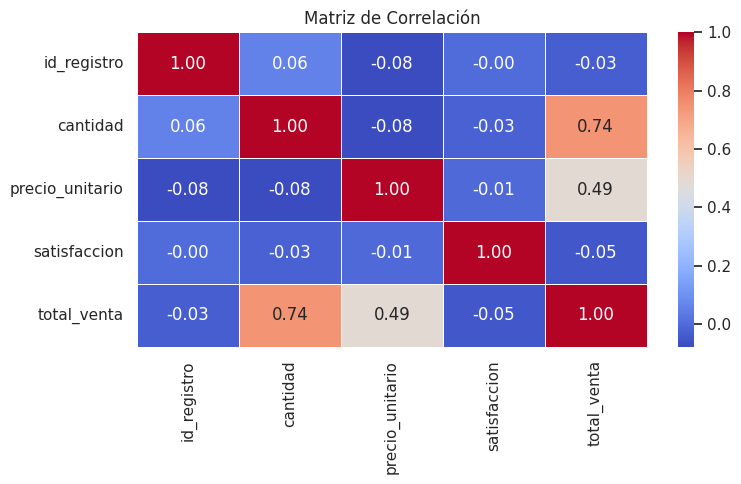

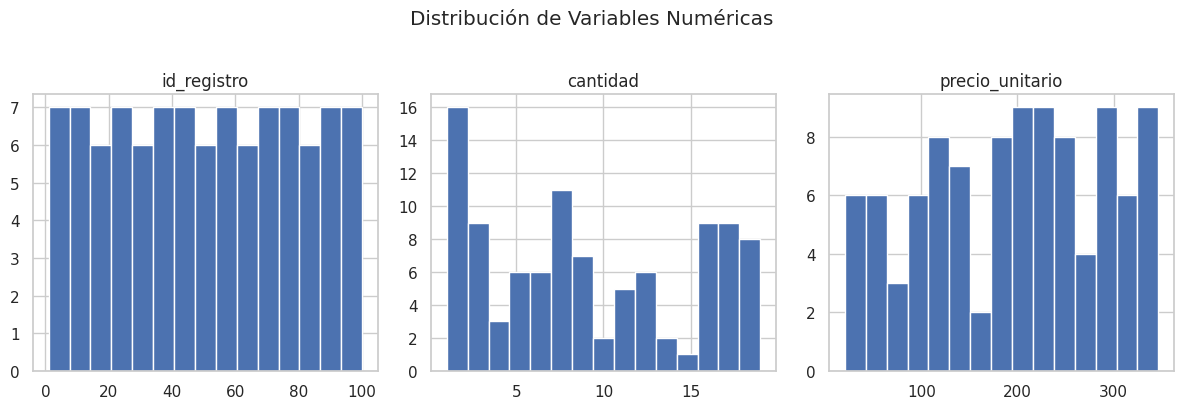

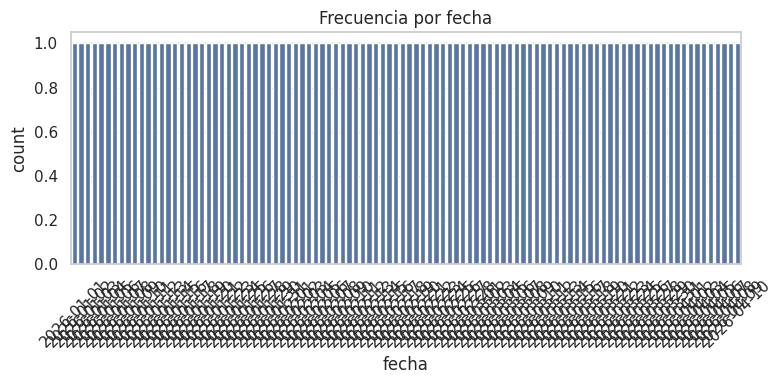

In [6]:
sns.set_theme(style='whitegrid')
cols_numericas = df.select_dtypes(include=[np.number]).columns.tolist()
cols_categoricas = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# 1. Mapa de calor de correlaciones (variables numéricas)
if len(cols_numericas) > 1:
  plt.figure(figsize=(8, 5))
  sns.heatmap(
      df[cols_numericas].corr(),
      annot=True,
      cmap='coolwarm',
      fmt='.2f',
      linewidths=0.5,
  )
  plt.title('Matriz de Correlación')
  plt.tight_layout()
  plt.show()

# 2. Histogramas de las primeras 3 variables numéricas
if cols_numericas:
  df[cols_numericas[:3]].hist(
      bins=15, figsize=(12, 4), layout=(1, min(3, len(cols_numericas)))
  )
  plt.suptitle('Distribución de Variables Numéricas', y=1.02)
  plt.tight_layout()
  plt.show()

# 3. Conteo de la primera variable categórica (si existe)
if cols_categoricas:
  plt.figure(figsize=(8, 4))
  sns.countplot(
      data=df,
      x=cols_categoricas[0],
      order=df[cols_categoricas[0]].value_counts().index,
  )
  plt.title(f'Frecuencia por {cols_categoricas[0]}')
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# Por defecto toma la última columna numérica; cámbiala por el nombre exacto de tu variable objetivo (ej. 'total_venta')
objetivo = df.select_dtypes(include=[np.number]).columns[-1]
print(f'Entrenando modelo para predecir: {objetivo}')

# Preparar variables (descartar fechas y convertir categorías a variables dummy)
X = df.drop(
    columns=[objetivo]
    + df.select_dtypes(include=['datetime64']).columns.tolist()
)
X = pd.get_dummies(X, drop_first=True)
y = df[objetivo]

# Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenar y evaluar
modelo = RandomForestRegressor(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)

print(f'R² (Precisión del ajuste): {r2_score(y_test, predicciones):.4f}')
print(
    f'Error Absoluto Medio (MAE): {mean_absolute_error(y_test, predicciones):.2f}'
)

Entrenando modelo para predecir: total_venta
R² (Precisión del ajuste): 0.9441
Error Absoluto Medio (MAE): 255.52


Dataset UDH generado: 1500 filas y 12 columnas


,estudiante_id,escuela_profesional,ciclo,promedio_ponderado_acumulado,promedio_ultimo_periodo,creditos_matriculados,creditos_aprobados,proporcion_avance,cursos_desaprobados_acumulados,cursos_repetidos_acumulados,tendencia_rendimiento,nivel_riesgo_t1
0,bb05b2d6fd,Medicina Humana,8,9.72,10.10,176,106,0.602,1,0,1.46,1
1,048ce1b265,Psicología,7,11.05,10.42,154,106,0.688,1,0,-1.75,2
2,902f7433cb,Medicina Humana,4,18.90,19.37,88,88,1.000,0,0,0.53,0
3,dd7b032219,Derecho,10,11.00,12.14,220,151,0.686,1,1,0.96,0
4,70198ba147,Administración,9,11.93,12.40,198,147,0.742,2,1,-0.17,1


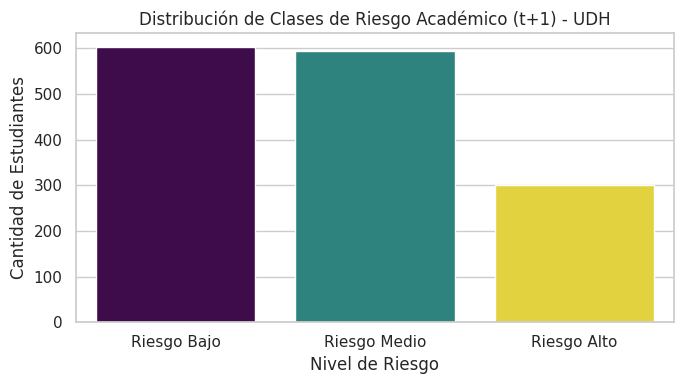

In [8]:
import hashlib

np.random.seed(42)


def generar_datos_udh(n_muestras=1500):
  escuelas = [
      'Ingeniería de Sistemas',
      'Derecho',
      'Administración',
      'Medicina Humana',
      'Psicología',
      'Arquitectura',
  ]
  data = []

  for i in range(1, n_muestras + 1):
    est_id = hashlib.sha256(f'ESTUDIANTE_UDH_{i}'.encode()).hexdigest()[:10]
    ciclo = np.random.randint(2, 11)
    escuela = np.random.choice(escuelas)

    promedio_ponderado_acumulado = np.clip(
        np.round(np.random.normal(loc=12.5, scale=2.5), 2), 5.0, 20.0
    )
    promedio_ultimo_periodo = np.clip(
        np.round(promedio_ponderado_acumulado + np.random.normal(0, 1.2), 2),
        0.0,
        20.0,
    )

    creditos_matriculados = ciclo * 22
    factor_aprobacion = np.clip(promedio_ponderado_acumulado / 16.0, 0.4, 1.0)
    creditos_aprobados = int(creditos_matriculados * factor_aprobacion)
    proporcion_avance = np.round(
        creditos_aprobados / creditos_matriculados, 3
    )

    cursos_desaprobados_acumulados = int(
        np.random.poisson(lam=max(0, (14 - promedio_ponderado_acumulado) * 0.8))
    )
    cursos_repetidos_acumulados = int(
        cursos_desaprobados_acumulados * np.random.choice([0, 0.5, 1])
    )

    promedio_penultimo_periodo = np.round(
        promedio_ultimo_periodo - np.random.normal(0.2, 0.8), 2
    )
    tendencia_rendimiento = np.round(
        promedio_ultimo_periodo - promedio_penultimo_periodo, 2
    )

    # Regla de etiquetado en t+1 (Sección 2.3)
    nota_t1_estimada = (
        promedio_ultimo_periodo
        + (tendencia_rendimiento * 0.5)
        + np.random.normal(0, 0.8)
    )

    if nota_t1_estimada >= 13.0 and cursos_desaprobados_acumulados <= 1:
      riesgo_t1 = 0  # Riesgo Bajo
    elif 11.0 <= nota_t1_estimada < 13.0 or cursos_desaprobados_acumulados in [
        2,
        3,
    ]:
      riesgo_t1 = 1  # Riesgo Medio
    else:
      riesgo_t1 = 2  # Riesgo Alto

    data.append({
        'estudiante_id': est_id,
        'escuela_profesional': escuela,
        'ciclo': ciclo,
        'promedio_ponderado_acumulado': promedio_ponderado_acumulado,
        'promedio_ultimo_periodo': promedio_ultimo_periodo,
        'creditos_matriculados': creditos_matriculados,
        'creditos_aprobados': creditos_aprobados,
        'proporcion_avance': proporcion_avance,
        'cursos_desaprobados_acumulados': cursos_desaprobados_acumulados,
        'cursos_repetidos_acumulados': cursos_repetidos_acumulados,
        'tendencia_rendimiento': tendencia_rendimiento,
        'nivel_riesgo_t1': riesgo_t1,
    })

  return pd.DataFrame(data)


df_udh = generar_datos_udh(n_muestras=1500)
print(
    f'Dataset UDH generado: {df_udh.shape[0]} filas y'
    f' {df_udh.shape[1]} columnas'
)
display(df_udh.head())

# Gráfico de distribución de clases (0: Bajo, 1: Medio, 2: Alto)
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df_udh,
    x='nivel_riesgo_t1',
    hue='nivel_riesgo_t1',
    palette='viridis',
    legend=False,
)
plt.title('Distribución de Clases de Riesgo Académico (t+1) - UDH')
plt.xticks(ticks=[0, 1, 2], labels=['Riesgo Bajo', 'Riesgo Medio', 'Riesgo Alto'])
plt.xlabel('Nivel de Riesgo')
plt.ylabel('Cantidad de Estudiantes')
plt.tight_layout()
plt.show()